In [1]:
# Datensätze wählen: die Zeilen der Datensätze, die nicht laufen sollen, auskommentieren. Jede weitere Zelle läuft für
# alle gewählten Datensätze und zeigt die Ergebnisse je Datensatz (helpers/datasets.py, per_dataset)
DATASETS = [
    "bpic17",   # BPIC2017: Kreditanträge einer niederländischen Bank
    #"bpic13",   # BPIC2013: IT-Incidents (Volvo IT)
    #"bpic19",   # BPIC2019: Einkauf (Bestellpositionen)
]

from helpers.datasets import load_dataset, per_dataset

# Je Datensatz Roh-Log, Angaben und Katalog der Interventionen (angezeigt)
loaded = per_dataset(DATASETS, load_dataset, show=lambda result: result[2])
logs = {dataset: log for dataset, (log, info, catalog) in loaded.items()}

### bpic17: Kreditanträge einer niederländischen Bank

bpic17: Kreditanträge einer niederländischen Bank
Outcome: Gewinn der Bank in €: bewilligt × Zinsertrag − Anrufe − Arbeitszeit − Durchlaufzeit (wie prescriptive/helpers/preprocessing/BPIC2017/outcome.py)
Log: eventlog/eventlog.xes.gz
Fälle 31,509, Events 1,202,267, Aktivitäten 26, Zeitraum 2016-01-01 bis 2017-02-01


,name,beschreibung,art,variable_typ,simulator,intervention,daten,hinweis
0,call,Anruf wegen fehlender Unterlagen,control_flow,NaN,umgesetzt,call,etwa 50 % der Runden,NaN
1,second_offer,Weiteres Angebot,control_flow,NaN,umgesetzt,second_offer,31 % der Fälle,NaN
2,channel,Versandkanal des Angebots,control_flow,NaN,moeglich,NaN,95 / 5 %; bewilligt 55 / 61 %,die seltene Option hat wenig Daten
3,call_after_offers,Nachfass-Anruf nach dem Angebot,control_flow,NaN,moeglich,NaN,fast jeder Fall mit Angebot,NaN
4,number_of_terms,Laufzeit des Angebots,variable,attribut,moeglich,NaN,36 bis 126 Monate; bewilligt 47 / 54 / 59 %,Abwägung Bewilligung gegen Zinsertrag; Umbau w...
5,Mitarbeiter: A_Denied,Wer A_Denied ausführt,variable,ressource,NaN,NaN,"3.752 Fälle, 99 Mitarbeiter (11 mit mindestens...","nur complete-Events, entschieden wird zum Zeit..."
6,Mitarbeiter: O_Accepted,Wer O_Accepted ausführt,variable,ressource,moeglich,NaN,"17.228 Fälle, 40 Mitarbeiter (31 mit mindesten...","nur complete-Events, entschieden wird zum Zeit..."
7,Mitarbeiter: W_Assess potential fraud,Wer W_Assess potential fraud ausführt,variable,ressource,moeglich,NaN,"301 Fälle, 36 Mitarbeiter (0 mit mindestens 10...","wenig Daten je Mitarbeiter, im Screening nicht..."
8,Mitarbeiter: W_Call incomplete files,Wer W_Call incomplete files ausführt,variable,ressource,umgesetzt,call,"15.003 Fälle, 67 Mitarbeiter (32 mit mindesten...",der Anrufer nach call (main.py --caller-choice...
9,Mitarbeiter: W_Complete application,Wer W_Complete application ausführt,variable,ressource,moeglich,NaN,"29.646 Fälle, 118 Mitarbeiter (76 mit mindeste...",der Mitarbeiter bearbeitet in derselben Sitzun...


In [2]:
# Hier preprocessing: das individuelle Preprocessing jedes gewählten Datensatzes (helpers/preprocessing/)
from helpers.preprocessing import preprocess

# Unvollständige Fälle entfernen
# Sortieren der Fälle
# Umrechnen der Zeitstempel
# Anpassungen je nach Datensatz
# Lifecycles wie im Log (BPIC17: schedule, start, suspend, resume, complete, ate_abort, withdraw der Arbeitsschritte W_),
# so wie Simulator, RCT-Daten und Schätzer sie haben (BPIC13 und BPIC19 haben nur complete-Events); bereinigt auf
# Arbeitsabschnitte start -> complete nur mit preprocess(..., work_sessions=True)
# Outcome wird abhängig vom Datensatz berechnet. Ist vordefiniert (outcome im Katalog); andere zur Wahl in OUTCOME
OUTCOME = {}   # je Datensatz eine der outcome_optionen des Katalogs statt des Standards, z. B. {"bpic17": "durchlaufzeit"}
logs = per_dataset(DATASETS, lambda dataset: preprocess(dataset, logs[dataset], outcome=OUTCOME.get(dataset)), show=False)

### bpic17: Kreditanträge einer niederländischen Bank

  drop_incomplete_cases           31,509 Fälle   1,202,267 Events | Fälle mit einem Event ohne Aktivität oder Zeitstempel ganz entfernen (der Ablauf hätte eine Lücke); Events ohne Fall-ID auch.
  naive_utc_timestamps            31,509 Fälle   1,202,267 Events | Zeitstempel naiv in UTC.
  sort_events                     31,509 Fälle   1,202,267 Events | Nach Fall und Zeit sortieren, stabil: bei gleicher Zeit bleibt die Reihenfolge im Log.
  ensure_lifecycle                31,509 Fälle   1,202,267 Events | Logs ohne Lifecycle-Spalte (z. B. BPIC19): alle Events sind complete-Events (der Simulator braucht Aktivität und Lifecycle).
  strip_activity_names            31,509 Fälle   1,202,267 Events | Leerzeichen am Rand von Aktivitätsnamen entfernen (BPIC17: "W_Shortened completion ").
Preprocessing bpic17: Fälle 31,509, Events 1,202,267, Aktivitäten 26, Zeitraum 2016-01-01 bis 2017-02-01
Outcome (profit): Gewinn der Bank in €: bewilligt × Zinsertrag − Anrufe − Arbeitszeit − Durchlaufzeit (wi

In [3]:
# Screening der Control-Flow-Kandidaten je gewähltem Datensatz (Stufen und Kennzahlen: helpers/screening/)
# Off policy evaluation mit XGBOOST, da schnell und einfach trainierbar

from helpers.screening import candidate_example, screen_control_flow, show_example

# Hier random beispiel ausgeben für vorverarbeiteten Case für Entscheidungspunkt X (helpers/screening/example.py): je
# gewähltem Datensatz ein zufälliger Fall für die Intervention, so wie das Screening ihn sieht: die Events (Prefix bis zum
# Entscheidungspunkt, danach nicht in X), die gewählte Option T, das Outcome Y und die Merkmale X (Spalte Confounder: Fall
# oder Prefix); dazu der Original-Fall aus dem Roh-Log neben dem vorverarbeiteten (Vergleich nach dem Preprocessing)
INTERVENTION = {"bpic17": "Mitarbeiter: O_Accepted"}   # je Datensatz ein Kandidat (Control Flow oder Variable); fehlt er: die Standard-Intervention
EXAMPLE_SEED = None                                      # None: bei jedem Lauf ein anderer Fall; eine Zahl: immer derselbe
examples = per_dataset(DATASETS, lambda dataset: candidate_example(dataset, logs[dataset], INTERVENTION.get(dataset), seed=EXAMPLE_SEED,
                                                                   raw_log=loaded[dataset][0]),
                       show=show_example)

### bpic17: Kreditanträge einer niederländischen Bank

,Wert
Kandidat,Mitarbeiter: O_Accepted
Art,resource
Fall,Application_11949550
Entscheidungs-Event,Nr. 99: O_Accepted (complete)
case:LoanGoal,Existing loan takeover
case:ApplicationType,New credit
case:RequestedAmount,19000.0
Option T,User_99
Outcome Y,2843.315
Fälle mit Entscheidungspunkt,"17,228"


**Merkmale X: so gehen sie in das Propensity-Modell** (59 Merkmale, Ziel: Option T)

,Merkmal,Confounder,Gruppe,Typ,Wert,lesbar
Nr.,,,,,,
1,case:LoanGoal,Fall,Fallattribut (gilt für den ganzen Fall),kategorial,Existing loan takeover,
2,case:ApplicationType,Fall,Fallattribut (gilt für den ganzen Fall),kategorial,New credit,
3,case:RequestedAmount,Fall,Fallattribut (gilt für den ganzen Fall),Zahl,19000.0,
4,last:OfferedAmount,Prefix,Event-Attribut: letzter Wert bis zum Entscheidungspunkt,Zahl,19000.0,
5,last:NumberOfTerms,Prefix,Event-Attribut: letzter Wert bis zum Entscheidungspunkt,Zahl,119.0,
6,last:MonthlyCost,Prefix,Event-Attribut: letzter Wert bis zum Entscheidungspunkt,Zahl,200.0,
7,last:FirstWithdrawalAmount,Prefix,Event-Attribut: letzter Wert bis zum Entscheidungspunkt,Zahl,0.0,
8,n:A_Accepted,Prefix,"Verlauf: so oft kam die Aktivität im Prefix vor (jedes Event, auch start)",Zahl,1,
9,n:A_Complete,Prefix,"Verlauf: so oft kam die Aktivität im Prefix vor (jedes Event, auch start)",Zahl,1,


**Original (Roh-Log)**: 102 Events, alle Spalten; Spalte Preprocessing: was daraus wird (0 entfernt)

,Preprocessing,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
Nr.,,,,,,,,,,,,,,,,,,,,
0,bleibt,Created,User_5,A_Create Application,Application,Application_11949550,complete,2016-08-01 18:52:14.779,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,
1,bleibt,Created,User_5,W_Complete application,Workflow,Workitem_1314381094,schedule,2016-08-01 18:52:14.790,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,
2,bleibt,Obtained,User_5,W_Complete application,Workflow,Workitem_1215492923,start,2016-08-01 18:52:14.793,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,
3,bleibt,statechange,User_5,A_Concept,Application,ApplState_2141472920,complete,2016-08-01 18:52:14.797,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,
4,bleibt,statechange,User_5,A_Accepted,Application,ApplState_641223548,complete,2016-08-01 18:54:35.359,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,
5,bleibt,Created,User_5,O_Create Offer,Offer,Offer_101939792,complete,2016-08-01 18:56:07.586,Existing loan takeover,New credit,Application_11949550,19000.0,0.0,119.0,False,200.0,True,692.0,19000.0,
6,bleibt,statechange,User_5,O_Created,Offer,OfferState_1351300792,complete,2016-08-01 18:56:08.224,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,Offer_101939792
7,bleibt,statechange,User_5,O_Sent (mail and online),Offer,OfferState_2135061896,complete,2016-08-01 18:56:23.856,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,Offer_101939792
8,bleibt,Deleted,User_5,W_Complete application,Workflow,Workitem_361600908,complete,2016-08-01 18:56:23.870,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,


**Nach dem Preprocessing**: 102 Events, alle Spalten; Teil: Prefix = bekannt am Entscheidungspunkt

,Teil,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID,outcome
Nr.,,,,,,,,,,,,,,,,,,,,,
0,Prefix,Created,User_5,A_Create Application,Application,Application_11949550,complete,2016-08-01 18:52:14.779,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,,2843.315343
1,Prefix,Created,User_5,W_Complete application,Workflow,Workitem_1314381094,schedule,2016-08-01 18:52:14.790,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,,2843.315343
2,Prefix,Obtained,User_5,W_Complete application,Workflow,Workitem_1215492923,start,2016-08-01 18:52:14.793,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,,2843.315343
3,Prefix,statechange,User_5,A_Concept,Application,ApplState_2141472920,complete,2016-08-01 18:52:14.797,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,,2843.315343
4,Prefix,statechange,User_5,A_Accepted,Application,ApplState_641223548,complete,2016-08-01 18:54:35.359,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,,2843.315343
5,Prefix,Created,User_5,O_Create Offer,Offer,Offer_101939792,complete,2016-08-01 18:56:07.586,Existing loan takeover,New credit,Application_11949550,19000.0,0.0,119.0,False,200.0,True,692.0,19000.0,,2843.315343
6,Prefix,statechange,User_5,O_Created,Offer,OfferState_1351300792,complete,2016-08-01 18:56:08.224,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,Offer_101939792,2843.315343
7,Prefix,statechange,User_5,O_Sent (mail and online),Offer,OfferState_2135061896,complete,2016-08-01 18:56:23.856,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,Offer_101939792,2843.315343
8,Prefix,Deleted,User_5,W_Complete application,Workflow,Workitem_361600908,complete,2016-08-01 18:56:23.870,Existing loan takeover,New credit,Application_11949550,19000.0,,,,,,,,,2843.315343


In [4]:
results = per_dataset(DATASETS, lambda dataset: screen_control_flow(dataset, logs[dataset]), show=lambda table: table.round(3))

### bpic17: Kreditanträge einer niederländischen Bank

call ...
second_offer ...
channel ...
call_after_offers ...


,Policy-Gewinn,KI unten,KI oben,Gewinn ggü. Bank,Bank KI unten,Bank KI oben,Überlappung,Placebo d,Ergebnis
Kandidat,,,,,,,,,
call,119.904,74.424,165.384,120.965,82.104,159.827,0.994,-0.010,ja
second_offer,-26.017,-64.404,12.370,134.310,92.743,175.878,0.989,0.010,nein: kein Policy-Gewinn gegenüber fester Regel
channel,125.850,-10.828,262.527,123.000,-12.313,258.313,0.055,-0.051,nein: kaum Überlappung
call_after_offers,9.898,6.781,13.014,17.256,13.566,20.947,0.000,0.024,nein: kaum Überlappung


In [5]:
# Screening der Variablen-Kandidaten je gewähltem Datensatz (Arten und Kennzahlen: helpers/screening/)
# Off policy evaluation mit XGBOOST, da schnell und einfach trainierbar; Variablen mit mehr als zwei Optionen
from helpers.screening import screen_variables, show_screening

# Pool der Mitarbeiter-Kandidaten ("Mitarbeiter: <Tätigkeit>", helpers/screening/candidates.py): je Fall wird nur unter
# den Mitarbeitern verglichen, die zum Zeitpunkt der Entscheidung (Startzeitpunkt des Arbeitsabschnitts) wählbar sind:
#   "kompetent"   wer die Tätigkeit laut Berechtigungsmodell des Datensatzes darf
#   "im Dienst"   kompetent und zu dem Zeitpunkt im Dienst (Dienstplan der Engine)
#   "frei"        im Dienst und in keinem anderen Arbeitsabschnitt (start -> complete), wie die Engine wählt
#   None          alle Mitarbeiter mit genug Fällen (bis 20), ohne Pool
# Überlappung zählt über die Fälle mit Wahl (mindestens zwei Optionen im Pool); Spalten Poolgröße Median, Fälle mit Wahl
POOL = "kompetent"
MIN_OVERLAP = 0.5
MIN_CASES_RESOURCES = 1  # eigene Schätzung für jeden Mitarbeiter mit so vielen Fällen (übrige zusammen als "other")

# Klick auf einen Mitarbeiter-Kandidaten in der Tabelle: seine Mitarbeiter mit Fällen, Anteil im Pool, Propensity und
# Anteil über der Schwelle
variables = per_dataset(DATASETS, lambda dataset: screen_variables(dataset, logs[dataset], pool=POOL, min_cases=MIN_CASES_RESOURCES,
                                                                   min_overlap=MIN_OVERLAP), show=show_screening)

### bpic17: Kreditanträge einer niederländischen Bank

number_of_terms ...
Mitarbeiter: A_Denied ...
Mitarbeiter: O_Accepted ...
Mitarbeiter: W_Assess potential fraud ...
Mitarbeiter: W_Call incomplete files ...
Mitarbeiter: W_Complete application ...
Mitarbeiter: W_Handle leads ...
Mitarbeiter: W_Validate application ...


In [ ]:
# Simulator aufstellen je gewähltem Datensatz (process-simulation-engine/simulation/dataset_simulator.py): ein Aufruf mit dem
# Datensatz; Ankünfte, Fallattribute, Mitarbeiter und Next-Event-Modell passen sich dem Datensatz an
# (je Baustein eine Tabelle, siehe dataset_simulator.py). Vorhandenes Modell oder Training.

# ---- Parameter für alle Datensätze (Standardwerte: helpers/parameters.py; was je Datensatz anders ist, steht im Katalog)
N_CASES = 2000            # simulierte Fälle je Lauf (Simulator-Check hier, Evaluation in der nächsten Zelle)
SEED = 0                  # Zufall der Simulation
HOURLY_RATE = 50.0        # € je Arbeitsstunde    } Kostensätze des Outcomes; wirken, wo das Outcome sie nutzt
DAILY_COST = 10.0         # € je Tag Durchlaufzeit } (Gewinn, BPIC17); die negativen Tage (BPIC13, BPIC19) kennen keine
SIM_INTERVENTION = {}     # je Datensatz eine andere Intervention als die Standard-Intervention, z. B. {"bpic13": "wait_user"}
RETRAIN = False           # True: das Next-Event-Modell neu trainieren, auch wenn eines vorhanden ist
SIM_TRAINING = {"width": 128, "depth": 2, "dropout": 0.1, "epochs": 80, "patience": 8, "seed": 42, "threads": 8}  # nur beim Training
COSTS = {"hourly_rate": HOURLY_RATE, "daily_cost": DAILY_COST}

from helpers.preprocessing import apply_costs, preprocess
from helpers.simulator_check import check_simulator
from simulation.dataset_simulator import build_simulator, simulator_work_sessions

# Outcome der echten Logs mit den gewählten Kosten (das Preprocessing rechnete mit den Standardwerten)
logs = {dataset: apply_costs(dataset, log, COSTS, OUTCOME.get(dataset)) for dataset, log in logs.items()}
# Der Simulator bekommt den Log, auf dessen Lifecycles sein Modell trainiert ist: die Lifecycles wie im Log (wie logs) oder,
# bei einem Modell auf Arbeitsabschnitten, mit der Bereinigung work_sessions; ebenso der Vergleich simuliert gegen echt
simulator_logs = {dataset: apply_costs(dataset, preprocess(dataset, loaded[dataset][0], verbose=False, work_sessions=True, outcome=OUTCOME.get(dataset)), COSTS, OUTCOME.get(dataset))
                  if simulator_work_sessions(dataset) else logs[dataset]
                  for dataset in DATASETS}
simulators = per_dataset(DATASETS, lambda dataset: build_simulator(dataset, simulator_logs[dataset], SIM_INTERVENTION.get(dataset), retrain=RETRAIN, **SIM_TRAINING),
                         show=False, heading=False)

# Simuliert gegen echt: wie die Bank, immer Option 0, immer Option 1
checks = per_dataset(DATASETS, lambda dataset: check_simulator(simulators[dataset], simulator_logs[dataset], n_cases=N_CASES, seed=SEED, costs=COSTS))

Vorhandenes Modell: models/next_event/lstm_time_act_restime_offers_caller23
DatasetSimulator(bpic17: Engine mit Mitarbeitern, Intervention call (Optionen ['no_call', 'call']), Ankünfte: neu gezogene Tage aus dem ganzen Log, Fallattribute: generator, Modell models/next_event/lstm_time_act_restime_offers_caller23)


### bpic17: Kreditanträge einer niederländischen Bank

simuliert, wie die Bank ...


/home/chair/henryks_students/laurens_ohl/Probabilistic_Suffix_Prescription/process-simulation-engine/.venv/lib/python3.11/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):
2026-10-26 10:55:24.585602: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_COMPAT_NOT_SUPPORTED_ON_DEVICE: forward compatibility was attempted on non supported HW
2026-10-26 10:55:24.585689: E external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:287] kernel version 580.126.18 does not match DSO version 580.178.4 -- cannot find working devices in this configuration


simuliert, immer no_call ...
simuliert, immer call ...


,echt,"simuliert, wie die Bank","simuliert, immer no_call","simuliert, immer call"
Fälle,31509.000,2000.000,2000.000,2000.000
Events je Fall,38.156,40.098,30.444,45.198
Aktivitäten,26.000,24.000,24.000,24.000
Durchlaufzeit (Tage),21.900,20.937,18.164,22.418
Entscheidung erreicht,0.694,0.726,0.724,0.716
Anteil Aktion,0.686,0.636,0.008,0.996
"Verzögerung bis Aktion, Median (h)",24.708,22.341,46.352,22.281
Outcome je Fall,1610.360,1731.435,1453.048,1786.575
Outcome mit Aktion,2475.684,2563.554,2315.724,2630.775
Outcome ohne Aktion,2416.292,2418.005,2126.736,953.066


### bpic17: Kreditanträge einer niederländischen Bank

echt  \
Bereich                    Kennzahl                                                         
Umfang                     Fälle                                                 31509.00   
                           Events                                              1202267.00   
                           verschiedene Aktivitäten                                 26.00   
Events pro Fall            Mittel                                                   38.16   
                           Median                                                   35.00   
                           P90                                                      60.00   
                           Maximum                                                 180.00   
Durchlaufzeit pro Fall     Mittel (h)                                              525.59   
                           Median (h)                                              458.11   
                           P75 (h)                                                 755.90   
                           P90 (h)                                                 841.32   
                           P95 (h)                                                1020.50   
                           Maximum (h)                                            6865.74   
Ankünfte pro Tag           Mittel                                                   86.09   
                           Median                                                   88.00   
                           P90                                                     126.00   
                           Maximum                                                 178.00   
Abschlüsse pro Tag         Mittel                                                   81.00   
                           Median                                                   79.00   
                           P90                                                     128.00   
                           Maximum                                                 527.00   
Kontrollfluss (Kanten)     Kanten Anzahl                                           178.00   
                           Kanten Überlappung (%)                                  100.00   
                           Kanten Jaccard (%)                                      100.00   
                           Kanten Top 20 getroffen                                  20.00   
                           Kanten Abstand der Anteile (%)                            0.00   
Trace-Varianten            Varianten Anzahl                                      15930.00   
                           Varianten Überlappung (%)                               100.00   
                           Varianten Jaccard (%)                                   100.00   
                           Varianten Top 10 getroffen                               10.00   
                           Fälle mit echter Variante (%)                           100.00   
                           Varianten nur complete: Anzahl                         5623.00   
                           Varianten nur complete: Jaccard (%)                     100.00   
                           Fälle mit echter Variante, nur complete (%)             100.00   
Aktivitätsverteilung       Aktivitäten Jaccard (%)                                 100.00   
                           Aktivitäten Abstand der Anteile (%)                       0.00   
Startaktivitäten           verschiedene Aktivitäten                                  1.00   
                           Abstand der Anteile (%)                                   0.00   
Endaktivitäten             verschiedene Aktivitäten                                 12.00   
                           Abstand der Anteile (%)                                   0.00   
Aktivitätsdauern           Aktivitäten mit mittlerer Dauer innerhalb ±25 %...       26.00   
                           mittlere Zeit bis zum nächsten Event (h)                 14

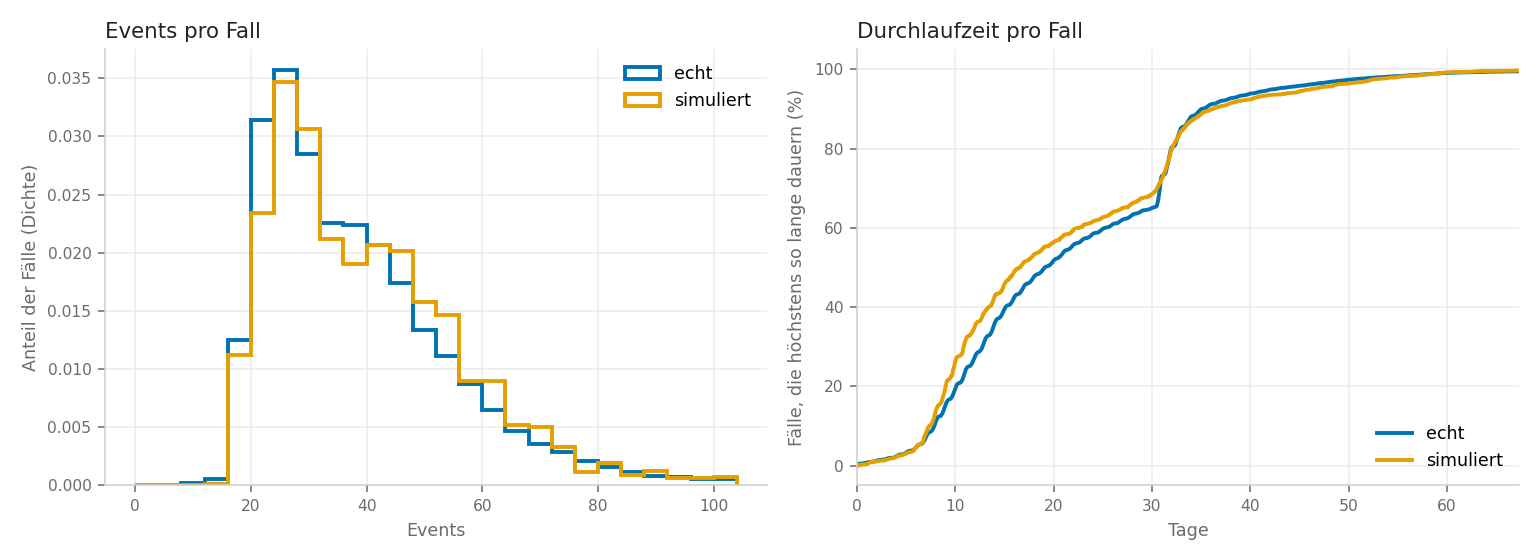

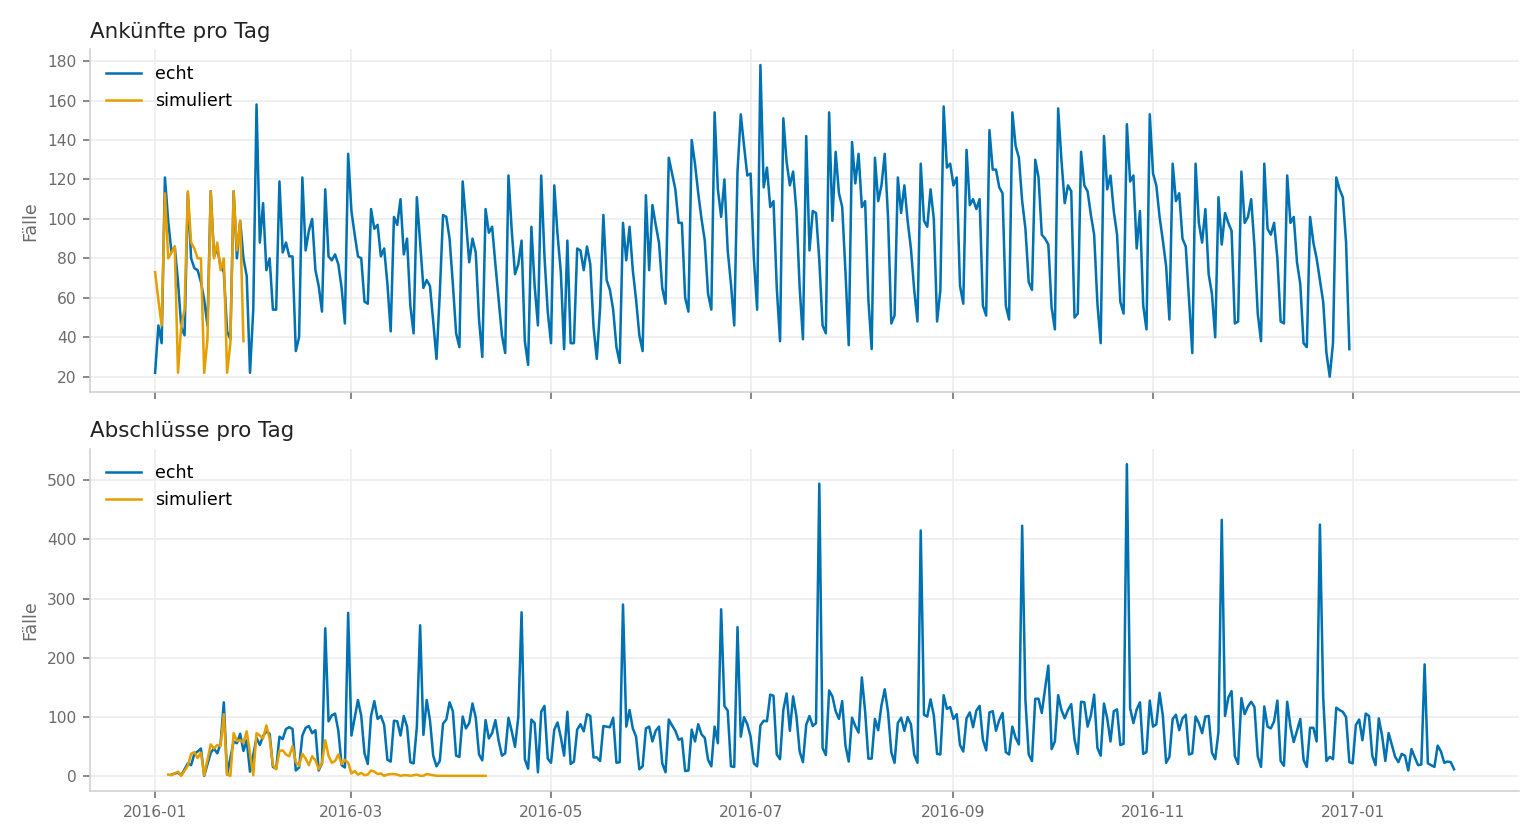

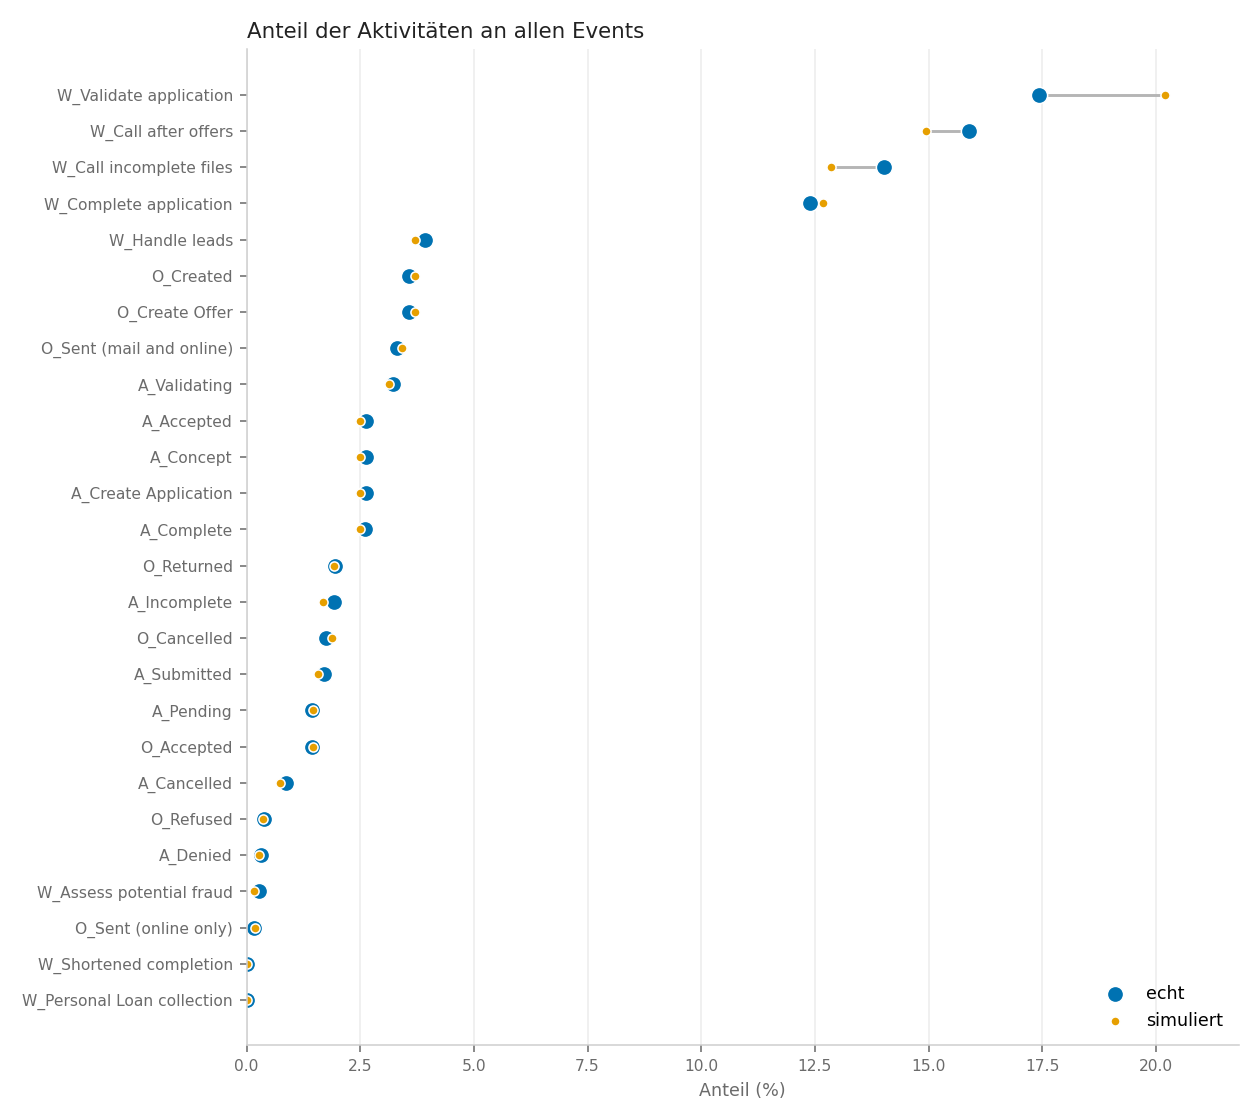

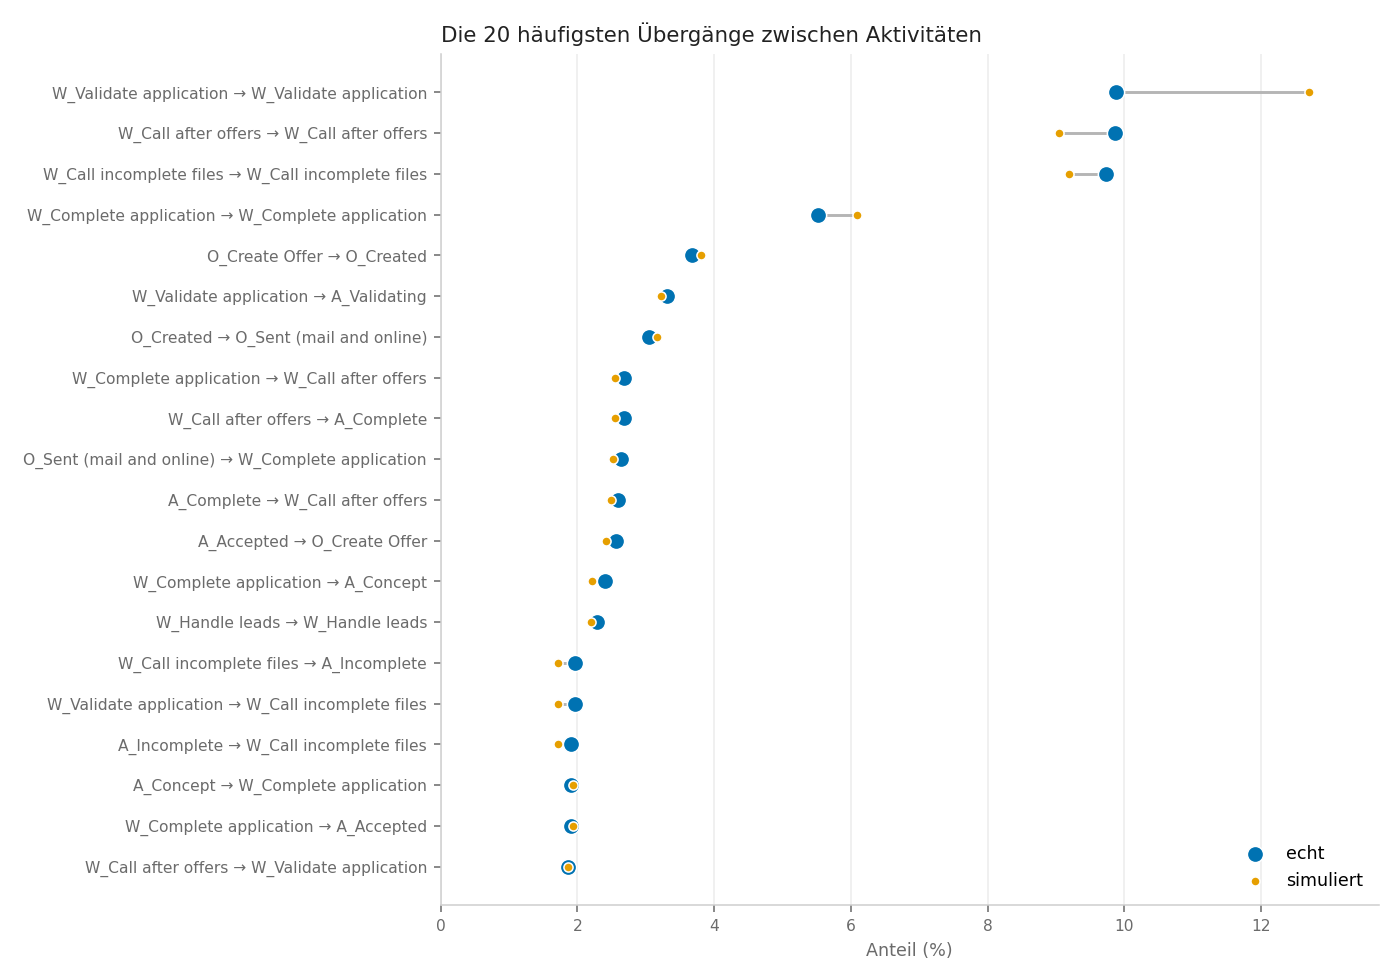

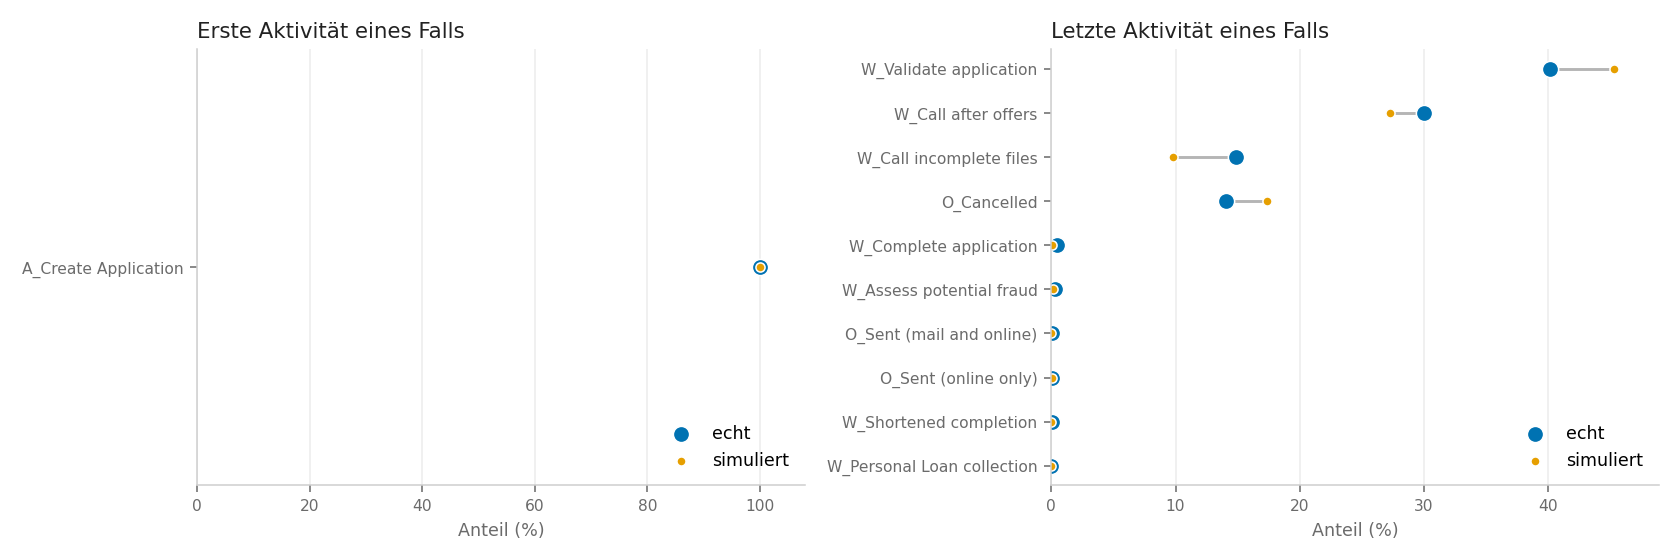

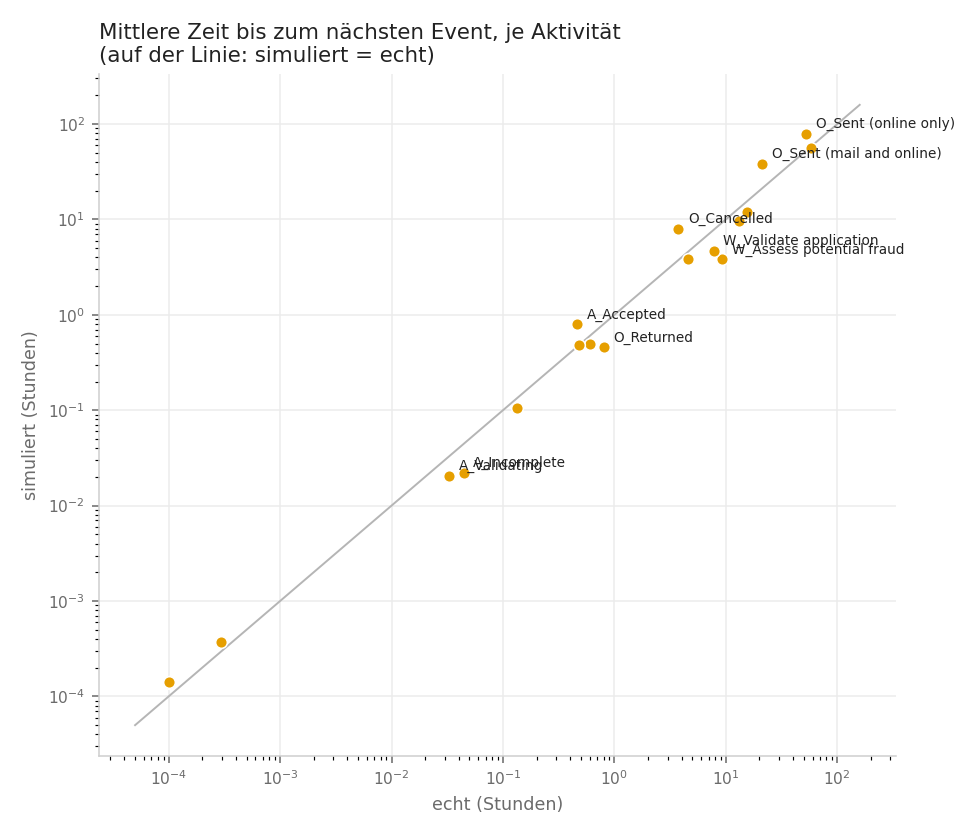

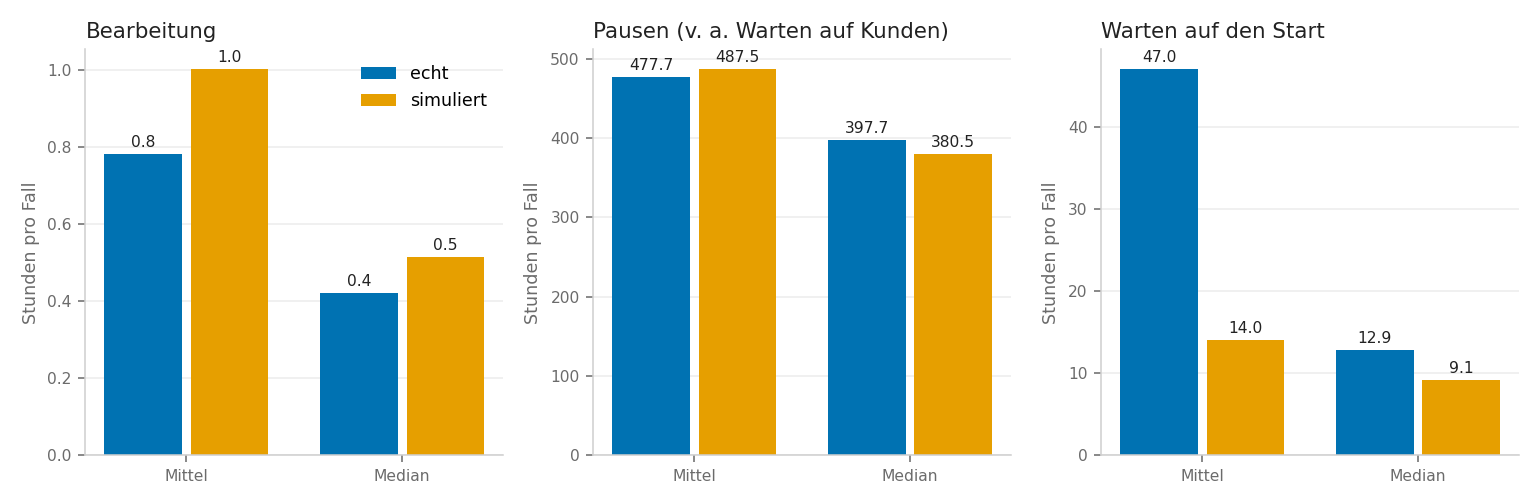

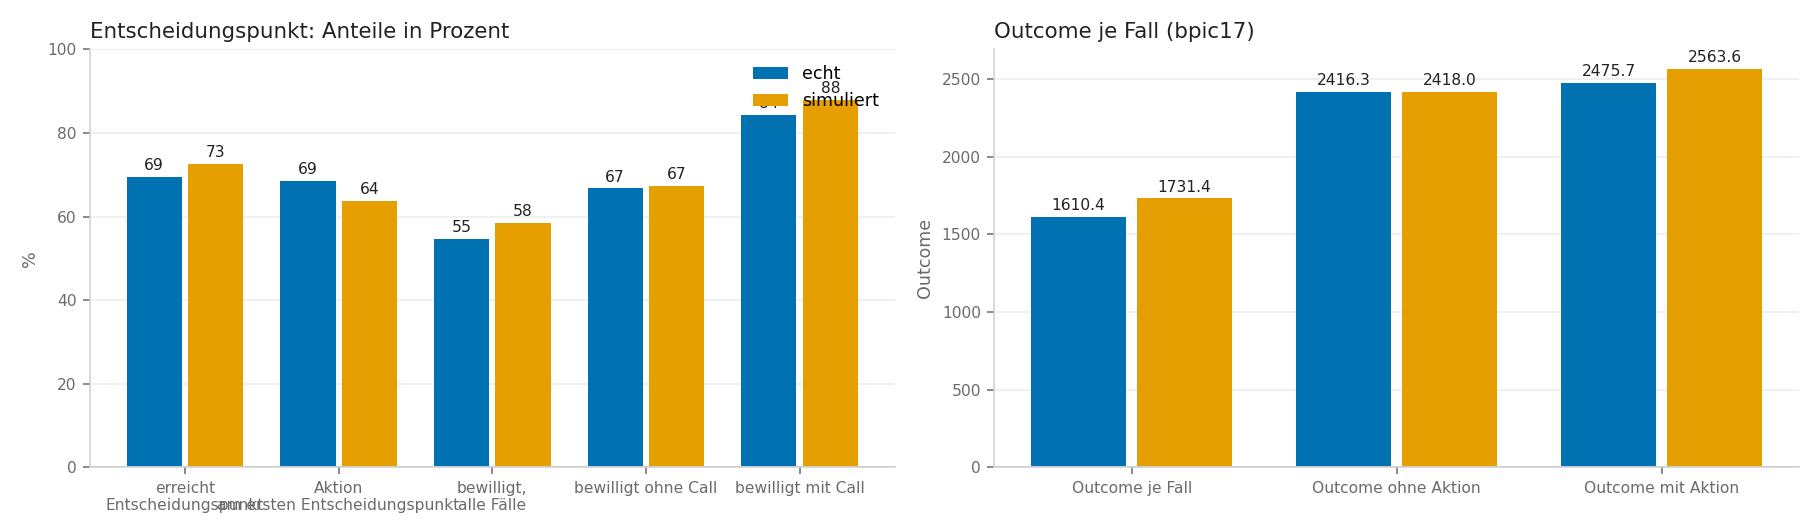

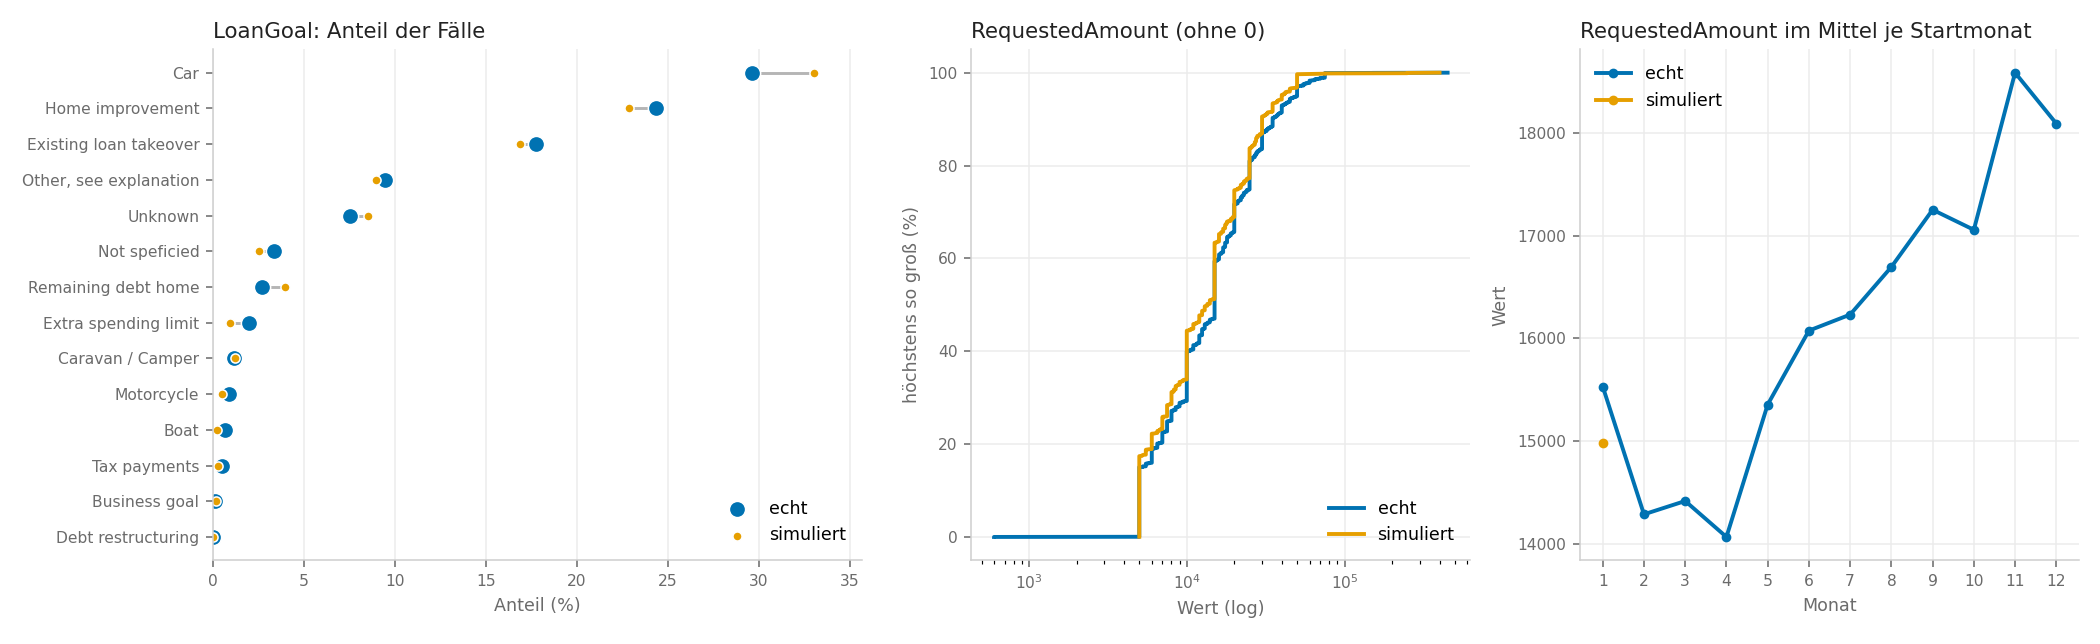

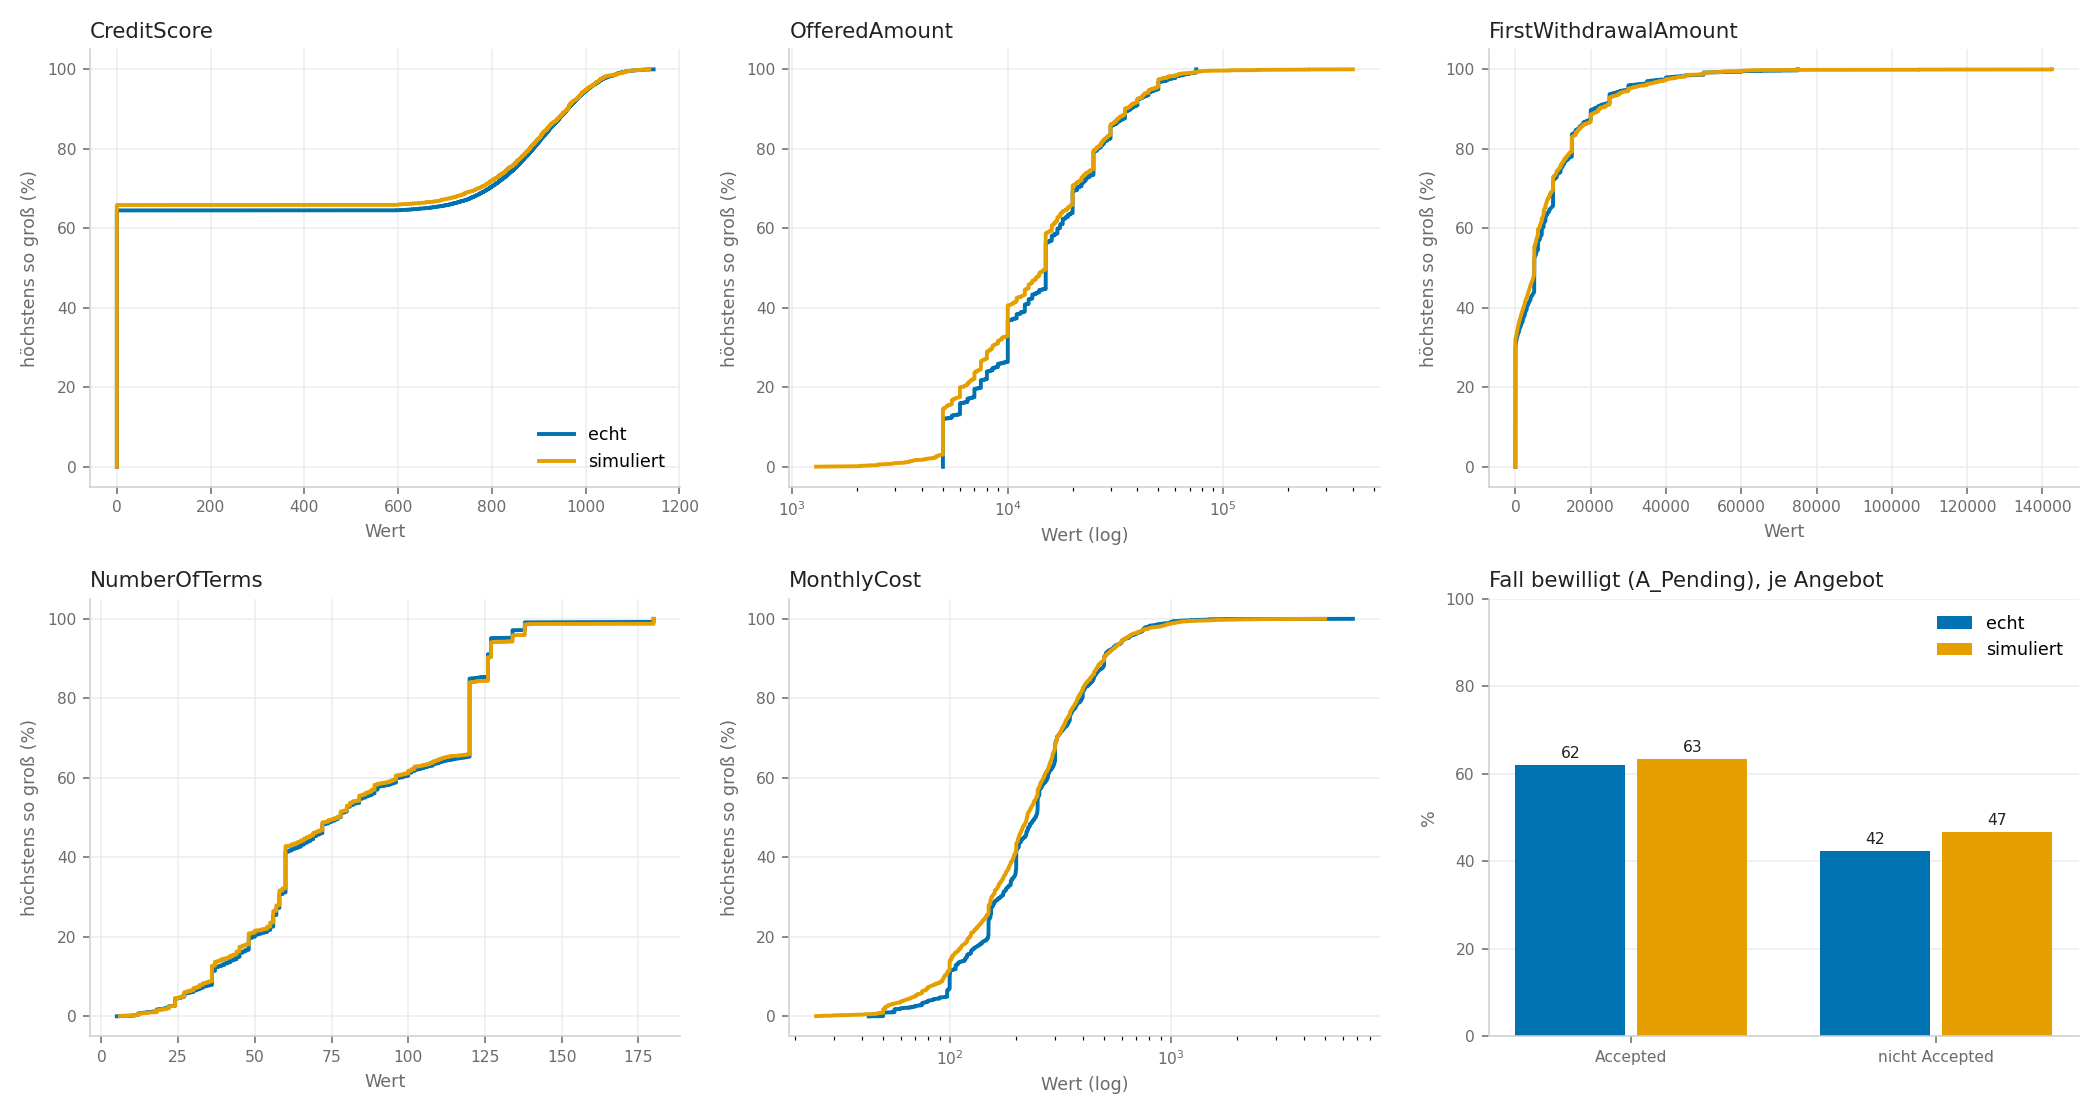

In [7]:
# Evaluation des Simulators je gewähltem Datensatz: die KPIs (process-simulation-engine/evaluation/evaluation.py, die
# bisherigen KPIs von BPIC17), simuliert wie die Bank und dem echten Event-Log gegenübergestellt; je Datensatz die Tabelle,
# dann die Diagramme. Was je Datensatz anders ist (Fallattribute, Arbeitsschritte, Systemnutzer, Entscheidungspunkt,
# Outcome), kommt aus seinen Einstellungen; nur BPIC17 hat dazu Angebote und Anrufer (evaluation/BPIC2017/). Parameter aus
# der Zelle davor (N_CASES, SEED, COSTS). Tabellen und Diagramme: prescriptive/data/evaluation/<datensatz>/
from helpers.simulator_check import evaluate_simulator

# Echter Log mit den Lifecycles wie der Simulator (simulator_logs aus der Zelle davor)
kpis = per_dataset(DATASETS, lambda dataset: evaluate_simulator(simulators[dataset], simulator_logs[dataset], n_cases=N_CASES, seed=SEED, costs=COSTS), show=False)

In [ ]:
# Random Case aus dem ECHTEN LOG
# (vorverarbeitetes Log) unter den Fällen, die den Entscheidungspunkt der Intervention des Simulators erreichen. Angezeigt:
# Fallattribute, Entscheidungspunkt, die Aktion dort im Log und das Outcome, dann alle Events mit Lifecycle.
# cases[datensatz]["prefix"]: die Events bis zum Entscheidungspunkt, also was zur Entscheidung bekannt ist.

# ---- Parameter
CASE_SEED = None          # None: bei jedem Lauf ein anderer Fall; eine Zahl: immer derselbe
CASE_IDS = {}             # je Datensatz ein bestimmter Fall statt eines zufälligen, z. B. {"bpic17": "Application_652823628"}

from helpers.cases import random_case, show_case

cases = per_dataset(DATASETS, lambda dataset: random_case(dataset, logs[dataset], simulators[dataset].intervention, seed=CASE_SEED,
                                                          case_id=CASE_IDS.get(dataset), costs=COSTS), show=show_case)

### bpic17: Kreditanträge einer niederländischen Bank

,Wert
Fall,Application_1195434598
Unter Fällen mit Entscheidungspunkt,"21,870"
case:LoanGoal,Unknown
case:ApplicationType,New credit
case:RequestedAmount,0.0
Events (davon complete),94 (30)
Entscheidungspunkt (A_Validating),"Event Nr. 19, nach 145.0 h"
Aktion im Log,call
Outcome,-1336.3
Ziel erreicht,False


,Aktivität,Lifecycle,Zeit,Mitarbeiter,Stunden seit Beginn,offer:OfferedAmount,offer:NumberOfTerms,offer:MonthlyCost,offer:FirstWithdrawalAmount,Entscheidung
Nr.,,,,,,,,,,
0,A_Create Application,complete,2016-05-17 07:53:44.850,User_15,0.00,NaN,NaN,NaN,NaN,
1,W_Complete application,schedule,2016-05-17 07:53:44.880,User_15,0.00,NaN,NaN,NaN,NaN,
2,W_Complete application,start,2016-05-17 07:53:44.883,User_15,0.00,NaN,NaN,NaN,NaN,
3,A_Concept,complete,2016-05-17 07:53:44.888,User_15,0.00,NaN,NaN,NaN,NaN,
4,A_Accepted,complete,2016-05-17 07:59:06.381,User_15,0.09,NaN,NaN,NaN,NaN,
...,...,...,...,...,...,...,...,...,...,...
89,A_Cancelled,complete,2016-06-07 13:08:19.414,User_3,509.24,75000.0,120.0,784.45,75000.0,
90,O_Cancelled,complete,2016-06-07 13:08:19.629,User_3,509.24,75000.0,120.0,784.45,75000.0,
91,O_Cancelled,complete,2016-06-07 13:08:19.644,User_3,509.24,75000.0,120.0,784.45,75000.0,


In [9]:
# Random Case aus Bank Policy (helpers/cases.py): je gewähltem Datensatz ein Lauf des Simulators wie die Bank (policy
# "bank": das Modell entscheidet die Aktion am Entscheidungspunkt wie im echten Log), aufbereitet wie der echte Log, und
# daraus ein zufälliger simulierter Fall unter denen, die den Entscheidungspunkt erreichen; angezeigt wie der echte Fall
# darüber. Simulator, N_CASES, SEED und COSTS aus der Zelle "Simulator aufstellen". bank_logs[datensatz]: der simulierte
# Log; bank_cases[datensatz]["prefix"]: die Events bis zum Entscheidungspunkt.

# ---- Parameter
BANK_CASE_SEED = None     # None: bei jedem Lauf ein anderer Fall; eine Zahl: immer derselbe
BANK_CASE_IDS = {}        # je Datensatz ein bestimmter simulierter Fall statt eines zufälligen (IDs aus bank_logs)

from helpers.cases import random_case, show_case, simulated_log

bank_logs = per_dataset(DATASETS, lambda dataset: simulated_log(simulators[dataset], N_CASES, "bank", SEED, costs=COSTS), show=False, heading=False)
bank_cases = per_dataset(DATASETS, lambda dataset: random_case(dataset, bank_logs[dataset], simulators[dataset].intervention, seed=BANK_CASE_SEED,
                                                               case_id=BANK_CASE_IDS.get(dataset), costs=COSTS), show=show_case)


### bpic17: Kreditanträge einer niederländischen Bank

,Wert
Fall,Application_615
Unter Fällen mit Entscheidungspunkt,"1,452"
case:LoanGoal,Caravan / Camper
case:ApplicationType,New credit
case:RequestedAmount,30000.0
Events (davon complete),63 (23)
Entscheidungspunkt (A_Validating),"Event Nr. 39, nach 715.6 h"
Aktion im Log,call
Outcome,5118.0
Ziel erreicht,True


,Aktivität,Lifecycle,Zeit,Mitarbeiter,Stunden seit Beginn,offer:OfferedAmount,offer:NumberOfTerms,offer:MonthlyCost,offer:FirstWithdrawalAmount,Entscheidung
Nr.,,,,,,,,,,
0,A_Create Application,complete,2016-01-10 10:22:46.531636,User_1,0.00,NaN,NaN,NaN,NaN,
1,A_Submitted,complete,2016-01-10 10:22:46.805073,User_1,0.00,NaN,NaN,NaN,NaN,
2,W_Handle leads,schedule,2016-01-10 10:22:47.410749,User_1,0.00,NaN,NaN,NaN,NaN,
3,W_Handle leads,withdraw,2016-01-10 10:23:39.974724,User_1,0.01,NaN,NaN,NaN,NaN,
4,W_Complete application,schedule,2016-01-10 10:23:40.286348,User_1,0.01,NaN,NaN,NaN,NaN,
...,...,...,...,...,...,...,...,...,...,...
58,O_Accepted,complete,2016-02-13 10:03:56.186457,User_2,815.69,30000.0,100.0,357.67,30000.0,
59,A_Pending,complete,2016-02-13 10:03:56.666581,User_2,815.69,30000.0,100.0,357.67,30000.0,
60,W_Call incomplete files,ate_abort,2016-02-13 10:03:56.734815,User_2,815.69,30000.0,100.0,357.67,30000.0,


In [17]:
# RCT-Daten auf dem Simulator je gewähltem Datensatz (helpers/rct.py): die Trainingsdaten der Schätzer (PSP, XGBoost, LSTM).
# Am ersten Entscheidungspunkt jedes Falls wird die Aktion zufällig gewählt (mit Anteil DELTA stattdessen wie die Bank);
# mit Engine (BPIC17) ist auch der Mitarbeiter am Arbeitsschritt der Intervention zufällig (bei call: der Anrufer), alle
# Fälle eines Laufs konkurrieren um die Mitarbeiter; ohne Engine (BPIC13, BPIC19) laufen die Fälle unabhängig.
# Simulator, Intervention und Kosten aus der Zelle "Simulator aufstellen" (simulators, COSTS). Gespeichert wie von main.py
# in prescriptive/data/<rct-Ordner>/log.pkl (BPIC17 call: rct_lc, BPIC13: bpic13_rct_<intervention>); vorhanden: geladen.

# ---- Parameter für alle Datensätze (Standardwerte: helpers/parameters.py)
RCT_CASES = None          # Fälle je Lauf (simuliertes Jahr); None: so viele, wie der echte Log Fälle hat
RCT_RUNS = 3              # Läufe (simulierte Jahre), je mit eigenem seed
RCT_SEED = 42             # Zufall der RCT-Läufe (Lauf r: RCT_SEED + 1000 + r)
DELTA = 0.0               # Anteil der ersten Entscheidungspunkte, die wie die Bank statt zufällig entschieden werden
WORKERS = 8               # parallele Simulationsprozesse (Engine: ein Lauf je Prozess)
REGENERATE = False        # True: neu simulieren und vorhandene RCT-Daten überschreiben

from helpers.rct import rct_summary, simulate_rct


# Je Datensatz die RCT-Daten (angereichertes Event-Log, enriched_log.enrich) und ihre Kennzahlen (angezeigt)
def rct_for(dataset):
    data = simulate_rct(simulators[dataset], n_cases=RCT_CASES, runs=RCT_RUNS, seed=RCT_SEED, delta=DELTA, workers=WORKERS,
                        costs=COSTS, regenerate=REGENERATE)
    return data, rct_summary(data, simulators[dataset].intervention)


rct = {dataset: data for dataset, (data, summary) in per_dataset(DATASETS, rct_for, show=lambda result: result[1]).items()}

### bpic17: Kreditanträge einer niederländischen Bank

RCT-Daten vorhanden, geladen: /home/chair/henryks_students/laurens_ohl/Probabilistic_Suffix_Prescription/prescriptive/data/rct_lc/log.pkl (erzeugt mit {'n_cases': 31509, 'runs': 3, 'seed': 42, 'delta': 0.0, 'intervention': 'call'}; neu erzeugen: regenerate=True)


,Wert
Fälle,94527.000
Events,3398946.000
Fälle mit Entscheidungspunkt,66406.000
davon randomisiert (Anteil),1.000
Outcome je Fall,1666.362
no_call: Anteil der Entscheidungspunkte,0.498
no_call: Outcome je Fall,2325.172
no_call: Ziel erreicht (Anteil),0.605
call: Anteil der Entscheidungspunkte,0.502
call: Outcome je Fall,2688.265


In [23]:
import importlib, helpers.parameters
importlib.reload(helpers.parameters)

<module 'helpers.parameters' from '/home/chair/henryks_students/laurens_ohl/Probabilistic_Suffix_Prescription/prescriptive/helpers/parameters.py'>

In [25]:
# Training der Schätzer auf den RCT-Daten je gewähltem Datensatz (helpers/training.py, wie main.py Block 2): PSP, XGBoost, LSTM.
# PSP zuerst: sein Split (zufällig nach Fällen) legt die Testfälle fest (test_cases.pkl im PSP-Ordner), die XGBoost und LSTM
# beim Training auslassen, damit alle offline auf denselben gehaltenen Fällen bewertet werden.
# Ordner in prescriptive/data: psp_<rct-Ordner><PSP_SUFFIX>, xgb_<rct-Ordner>, lstm_<rct-Ordner> (BPIC17 call: psp_rct_lc, ...);
# vorhanden: geladen. Die Offline-Auswertung (nächste Zelle) findet die Modelle danach selbst.
# Braucht simulators aus der Zelle "Simulator aufstellen" und rct aus der Zelle davor.

# ---- Parameter (Standardwerte: helpers/parameters.py)
ESTIMATORS = ("psp", "xgb", "lstm")  # zu trainierende Schätzer
PSP_SUFFIX = ""           # Zusatz des PSP-Ordners für eine Variante (z. B. "_static")
PSP_OPTIONS = {}          # Abweichungen von helpers/training.py PSP_OPTIONS, z. B. {"psp_decoder_static": True}
PSP_EPOCHS = 30           # Trainingsepochen des PSP
PSP_LEARNING_RATE = 1e-4  # Start-Lernrate des PSP
PSP_MIN_CALLS = 100       # Mitarbeiter mit mindestens so vielen ersten Arbeitsschritten im RCT bekommen ein eigenes Token
TRAIN_SEED = 42           # Zufall von XGBoost und LSTM
RETRAIN = False           # True: neu trainieren (beim PSP auch neu vorverarbeiten) und vorhandene Modelle überschreiben

from helpers.training import train_estimators


def train_for(dataset):
    return train_estimators(simulators[dataset], rct[dataset], estimators=ESTIMATORS, delta=DELTA, psp_suffix=PSP_SUFFIX,
                            psp_options=PSP_OPTIONS, epochs=PSP_EPOCHS, learning_rate=PSP_LEARNING_RATE, min_calls=PSP_MIN_CALLS,
                            workers=WORKERS, seed=TRAIN_SEED, retrain=RETRAIN)


trainings = per_dataset(DATASETS, train_for)


### bpic17: Kreditanträge einer niederländischen Bank

Mitarbeiter mit eigenem Token: 91 (mindestens 100 erste Arbeitsschritte im RCT)
psp: Training ...


/home/chair/henryks_students/laurens_ohl/Probabilistic_Suffix_Prescription/probabilistic_suffix_prediction_U-ED-LSTM/src/event_log_loader/new_event_log_loader_v2.py:71: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  applied = df.groupby(key, sort=sort).apply(func)


MemoryError: 

In [22]:
# Offline Auswertung aller Modelle auf dem echten Event-Log (evaluation/model_evaluation.py), derzeit nur die Wahl des
# Mitarbeiters: je gewähltem Datensatz an einem wählbaren Interventionspunkt (die Mitarbeiter-Kandidaten des Katalogs,
# Tabelle oben in der Ausgabe). Wer wählt den Mitarbeiter besser als die Bank? Der Wert jeder Policy wird mit AIPW aus dem
# Log geschätzt (Propensity der Bank und Outcome-Modell mit XGBoost und Cross-Fitting, wie im Screening), je Fall nur unter
# den Mitarbeitern seines Pools. Gewählt wird unter den Mitarbeitern mit eigener Option (wie im Screening: genug Fälle und
# meist über der Schwelle der Überlappung); die übrigen (other) sind im Log kaum vergleichbar gewählt worden.
# Policies: Bank (beobachtet), Zufall, DR-Learner auf dem echten Log (Cross-Fitting) und die gewählten Prescriptive-Modelle
# (PRESCRIPTIVE_MODEL: PSP, XGBoost, LSTM) der Intervention des Simulators, zu der der Interventionspunkt gehört (BPIC17:
# "Mitarbeiter: W_Call incomplete files" zu call, Modelle auf den RCT-Daten); an anderen Interventionspunkten nur die ersten drei.
# Spalten: Gewinn je Fall und ggü. Bank mit 95-%-Intervall; wie die Bank: Anteil mit demselben Mitarbeiter; Wahl gestützt:
# Anteil, in dem die Bank den gewählten Mitarbeiter in solchen Fällen mit mehr als 0,1 / Poolgröße wählt (darunter ist der
# Wert extrapoliert, das Intervall wird breit); mit Schätzung: Rest hat das Modell nicht bewertet, dort entscheidet die Bank.
# Werte je Modell: prescriptive/data/eval/models_<datensatz>/, beim nächsten Lauf mit denselben Einstellungen geladen.
# Braucht logs und COSTS aus der Zelle "Simulator aufstellen".

# ---- Parameter
PRESCRIPTIVE_MODEL = "psp"  # Prescriptive-Modell(e): eine Art ("psp", "xgb", "lstm": alle Modelle dieser Art), ein Ordner
                            # (Spalte Namen der Tabelle, z. B. "psp_rct_ce_l2_static_bw10"), eine Liste davon oder None (alle) 
EVAL_POINT = {"bpic17": "Mitarbeiter: W_Call incomplete files"}  # je Datensatz der Interventionspunkt; fehlt er: der erste mit Modellen
EVAL_POOL = "frei"        # Pool je Fall wie im Screening: "kompetent", "im Dienst" oder "frei"
EVAL_MAX_CASES = 2000     # höchstens so viele Fälle mit Wahl (zufällig, für alle Policies dieselben); None: alle
EVAL_SAMPLES = 100        # PSP: gezogene Suffixe je Fall und Mitarbeiter
OTHER_CHOOSABLE = False   # True: auch Mitarbeiter ohne eigene Option (other) sind wählbar
EVAL_WORKERS = 8          # parallele Prozesse für das PSP
RECOMPUTE = False         # True: die Werte der Modelle neu berechnen statt sie zu laden

from IPython.display import display

from prescriptive.evaluation.model_evaluation import evaluate_models, resource_points


# Je Datensatz: die wählbaren Interventionspunkte mit ihren Modellen (angezeigt), dann die Auswertung am gewählten
def evaluate_for(dataset):
    points = resource_points(dataset)
    display(points)
    point = EVAL_POINT.get(dataset) or (list(points.index[points["Modelle"] > 0]) + list(points.index))[0]
    return evaluate_models(dataset, logs[dataset], point, models=PRESCRIPTIVE_MODEL, pool=EVAL_POOL, other_choosable=OTHER_CHOOSABLE,
                           max_cases=EVAL_MAX_CASES, samples_per_action=EVAL_SAMPLES, workers=EVAL_WORKERS, costs=COSTS, recompute=RECOMPUTE)


evaluations = per_dataset(DATASETS, evaluate_for, show=lambda table: table.round(3))

### bpic17: Kreditanträge einer niederländischen Bank

,Entscheidung,Intervention,Modelle,Namen
Interventionspunkt,,,,
Mitarbeiter: A_Denied,A_Denied,,0,
Mitarbeiter: O_Accepted,O_Accepted,,0,
Mitarbeiter: W_Assess potential fraud,W_Assess potential fraud,,0,
Mitarbeiter: W_Call incomplete files,W_Call incomplete files,call,23,"psp_rct, psp_rct3x, psp_rct_delta50, psp_rct_d..."
Mitarbeiter: W_Complete application,W_Complete application,,0,
Mitarbeiter: W_Handle leads,W_Handle leads,,0,
Mitarbeiter: W_Validate application,W_Validate application,,0,


Mitarbeiter: W_Call incomplete files: Fälle, Pools (frei) und Optionen aus dem echten Log ...


KeyboardInterrupt: 

In [ ]:
# Online_eval
# Lagebild des PSP auf dem Simulator (helpers/overview.py, prescriptive/overview.py): Der Simulator gibt die Umgebung vor,
# alle Fälle laufen gemeinsam in der Engine und konkurrieren um die Mitarbeiter; es entscheidet die Bank (policy bank).
# Das PSP steht über den laufenden Fällen: alle OVERVIEW_EVERY_HOURS zieht es für jeden laufenden Fall Suffixe (neu nur
# für Fälle mit neuen Events, die übrigen behalten ihre) und hält so eine Übersicht über alle Prozesse. Ist die Aktion am
# Entscheidungspunkt noch offen (die Bank entscheidet verdeckt, die Aktion ist noch nicht zu sehen), zieht es je Aktion
# und gewichtet mit dem Anteil der Aktion im echten Log. Das Lagebild ändert den Verlauf nicht (eigene Zufallszahlen).
# Angezeigt: je Beobachtung die Zusammenfassung über alle laufenden Fälle (Phasen, erwartete Abschlüsse in 1 und 7 Tagen,
# Bewilligungen, offene Anrufe und Arbeitsstunden), die Güte der Prognosen gegen den simulierten Verlauf (je Phase) und
# die erwarteten gegen die tatsächlichen Abschlüsse je Beobachtung. Nur Datensätze mit Engine (BPIC17).
# overviews[datensatz]["overview"].snapshots: je Beobachtung und Fall die Prognose; .suffixes: die Suffixe des letzten Stands.
# Braucht simulators und COSTS aus der Zelle "Simulator aufstellen".

# ---- Parameter
OVERVIEW_MODEL = {"bpic17": "psp_rct_ce_l2_static_bw10"}  # je Datensatz das PSP-Modell (Ordner in prescriptive/data)
OVERVIEW_CASES = 2000      # simulierte Fälle (Ankünfte)
OVERVIEW_EVERY_HOURS = 24  # Abstand der Beobachtungen in simulierten Stunden
OVERVIEW_SAMPLES = 20      # gezogene Suffixe je Fall (und je Aktion, solange sie offen ist)
OVERVIEW_WORKERS = 8       # parallele Prozesse für das PSP
OVERVIEW_SEED = SEED       # Zufall der Simulation und des PSP

from IPython.display import Markdown, display

from helpers.overview import simulate_overview


def overview_for(dataset):
    if dataset not in OVERVIEW_MODEL:
        print(f"{dataset}: kein PSP-Modell in OVERVIEW_MODEL")
        return None
    result = simulate_overview(simulators[dataset], OVERVIEW_MODEL[dataset], n_cases=OVERVIEW_CASES, every_hours=OVERVIEW_EVERY_HOURS,
                               samples=OVERVIEW_SAMPLES, workers=OVERVIEW_WORKERS, seed=OVERVIEW_SEED, costs=COSTS)
    display(Markdown("**Lagebild je Beobachtung**"), result["overview"].summary.round(1))
    display(Markdown("**Güte der Prognosen je Phase**"), result["quality"]["cases"].round(3))
    display(Markdown("**Abschlüsse: erwartet gegen tatsächlich**"), result["quality"]["portfolio"].round(1))
    return result


overviews = per_dataset(DATASETS, overview_for, show=False)